# Shot probability: model comparison

Seven models, the same 49 predictors, and the existing chronological development split.
This notebook **fits the challengers**, reproduces the saved site model, and evaluates all of them on the same validation shots. Run **Kernel → Restart Kernel and Run All Cells** to reproduce it. Each run writes a new timestamped directory under `reports/model_comparison/`.

| Model | Purpose |
| --- | --- |
| Training make rate | Constant probability baseline |
| Saved boosted trees | Unchanged 49-feature site benchmark |
| Logistic regression | Regularized linear effects on log odds |
| Spline logistic | Smooth additive effects for location and selected histories |
| Extra Trees | Randomized trees with interactions |
| CatBoost | A second gradient-boosted tree implementation |
| Explainable boosting | Nonlinear additive effects plus five explicit interactions |

This is a fixed-configuration screening experiment, not an exhaustive ranking of model families. No challenger changes the site selection. No test-period outcomes are loaded, no calibration adjustment is fitted, and no validation-driven early stopping is used.

## Environment

Use the personal project's `.venv` kernel. Dependencies are pinned in `requirements-model-comparison.txt` on top of the existing project requirements:

```bash
.venv/bin/python -m pip install -r requirements-model-comparison.txt
.venv/bin/python -m jupyter lab HaydenModelComparison.ipynb
```

The notebook requires the local frozen data and model artifacts; it does not download basketball data. CatBoost and InterpretML are required, rather than silently skipped. Training uses up to four CPU threads.

In [1]:
import os
import sys
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path('/Users/haydenkellington/Desktop/EclipseHaydenPersonal').resolve()
assert Path(sys.prefix).resolve() == ROOT / '.venv', 'Select the personal project .venv kernel.'
assert ROOT.name == 'EclipseHaydenPersonal' and ROOT.is_dir()
assert not any((p / '.git').exists() for p in [ROOT, *ROOT.parents])
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = ROOT / 'reports' / 'model_comparison' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / 'models').mkdir()
(RUN_DIR / 'figures').mkdir()
for name, value in {'OMP_NUM_THREADS': '4', 'OPENBLAS_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1',
                    'MPLCONFIGDIR': str(RUN_DIR / '.matplotlib')}.items():
    os.environ[name] = value
sys.path.insert(0, str(ROOT / 'scripts'))

import hashlib
import importlib.metadata
import json
import time
import warnings
import joblib
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from catboost import CatBoostClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from threadpoolctl import threadpool_limits
from train_baselines import METRICS, TARGET, bootstrap_model, score_predictions, sha256
from shooting_profile_features import ShootingProfileFeatureBuilder, QUERY_COLUMNS

SEED = 20261115
THREADS = 4
REFERENCE = 'saved_boosted_trees'
LABELS = {
    'training_make_rate': 'Training make rate',
    REFERENCE: 'Saved boosted trees',
    'logistic': 'Logistic regression',
    'spline_logistic': 'Spline logistic',
    'extra_trees': 'Extra Trees',
    'catboost': 'CatBoost',
    'ebm': 'Explainable boosting',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
VERSIONS = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'catboost', 'interpret-core', 'joblib',
             'matplotlib', 'pyarrow', 'nbformat', 'nbclient', 'threadpoolctl']}
print('Run:', RUN_DIR)
display(pd.Series(VERSIONS, name='version').to_frame())

Matplotlib is building the font cache; this may take a moment.


Run: /Users/haydenkellington/Desktop/EclipseHaydenPersonal/reports/model_comparison/20261116T043706371489Z


,version
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
catboost,1.2.10
interpret-core,0.7.8
joblib,1.6.0
matplotlib,3.11.2
pyarrow,26.0.0
nbformat,5.11.1
nbclient,0.11.0


## Frozen inputs and chronology

The feature table is the previously verified output of the shared training/site builders. Its historical hash, saved predictions, source manifests, and benchmark identity are checked before fitting. Histories exclude the **entire shot date**, follow stable IDs across trades, and retain the existing previous-season fallbacks and playoff rules. Source year `2025` still means **2024–25**.

Earlier validation dates may contribute to later validation histories under the existing daily-updating prediction policy. Model coefficients stay fixed; histories are not frozen at the training cutoff. The source is a retrospective snapshot and can include later data corrections.

In [2]:
selection = json.loads((ROOT / 'models/matchup_model.json').read_text())
historical_pins = json.loads((ROOT / 'reports/shooting_profile/protected_artifacts.json').read_text())
INPUTS = [
    'models/matchup_model.json', selection['model_path'],
    'reports/matchup_model/development_features.parquet',
    'reports/matchup_model/validation_predictions.parquet',
    'reports/matchup_model/bootstrap_game_draws.npz',
    'reports/matchup_model/manifest.json',
    'reports/matchup_model/inference_verification.json',
    'reports/matchup_model/defender_audit.json',
    'data/external/llimllib_snapshot_v1/manifest.json',
    'data/external/nba_defender_snapshot_v1/manifest.json',
    'data/processed/nba_shots_clean.parquet',
]
input_hashes = {}
for relative in INPUTS:
    file = ROOT / relative
    assert file.is_file() and not file.is_symlink(), relative
    actual = sha256(file)
    assert relative in historical_pins and actual == historical_pins[relative], relative
    input_hashes[relative] = actual
assert input_hashes[selection['model_path']] == selection['model_sha256']

# Record every existing model, data file and prior report to detect accidental changes.
protected = {}
for folder in ['models', 'data', 'reports']:
    for file in (ROOT / folder).rglob('*'):
        if file.is_file() and 'model_comparison' not in file.relative_to(ROOT).parts:
            protected[str(file.relative_to(ROOT))] = sha256(file)
(RUN_DIR / 'protected_artifacts.json').write_text(json.dumps(protected, indent=2))

bundle = joblib.load(ROOT / selection['model_path'])
FEATURES = list(selection['features'])
assert len(FEATURES) == 49 and FEATURES == bundle['features']
assert set(FEATURES).isdisjoint({TARGET, 'game_id', 'game_event_id', 'game_date', 'split',
                               'player_id', 'defender_id', 'raw_action_type', 'recorded_period'})
META = ['game_id', 'game_event_id', 'game_date', 'split', 'player_id', 'defender_id', 'defender_mapping_available']
frame = pd.read_parquet(ROOT / INPUTS[2], columns=META + FEATURES + [TARGET])
frame['game_date'] = pd.to_datetime(frame.game_date)
assert set(frame.split) == {'train', 'validation'}
assert not frame.duplicated(['game_id', 'game_event_id']).any()
assert frame.groupby('game_id').split.nunique().eq(1).all()
assert frame.groupby('game_id').game_date.nunique().eq(1).all()
assert not frame[FEATURES + [TARGET]].isna().any().any()
assert set(frame[TARGET].unique()) == {0, 1}
frame = frame.sort_values(['game_date', 'game_id', 'game_event_id']).reset_index(drop=True)
train = frame.loc[frame.split.eq('train')].reset_index(drop=True)
validation = frame.loc[frame.split.eq('validation')].reset_index(drop=True)
assert len(train) == 340288 and len(validation) == 85110
assert train.game_date.max() == pd.Timestamp('2026-01-13')
assert validation.game_date.min() == pd.Timestamp('2026-01-14')
assert validation.game_date.max() == pd.Timestamp('2026-03-23')
assert train.game_date.max() < validation.game_date.min()
assert set(train.game_id).isdisjoint(validation.game_id)

prior_manifest = json.loads((ROOT / 'reports/matchup_model/manifest.json').read_text())
replay = json.loads((ROOT / 'reports/matchup_model/inference_verification.json').read_text())
assert replay['all_49_features_exactly_match_saved_development_data']
assert replay['test_outcomes_read'] == 0
assert prior_manifest['context_audit']['same_or_future_date_cutoff_violations'] == 0
assert prior_manifest['defender_audit']['same_or_future_date_cutoff_violations'] == 0
split_summary = frame.groupby('split', sort=False).agg(
    shots=(TARGET, 'size'), games=('game_id', 'nunique'),
    first_date=('game_date', 'min'), last_date=('game_date', 'max'), make_rate=(TARGET, 'mean'))
display(split_summary)
print(f'49 frozen features; {len(protected):,} protected artifacts; test rows loaded: 0')

,shots,games,first_date,last_date,make_rate
split,,,,,
train,340288,1909,2024-10-22,2026-01-13,0.46741
validation,85110,480,2026-01-14,2026-03-23,0.469722


49 frozen features; 2,943 protected artifacts; test rows loaded: 0


## Model definitions

All candidates use exactly the same 49 input columns and all training rows. Scaling, spline knots, category vocabularies and fitted effects come from training only. Settings below are declared before viewing the new results; there is no hyperparameter search in this run.

Spline logistic uses cubic univariate bases plus linear terms and one-hot categories: it is an additive logistic model, **not** a Bayesian hierarchical model or a two-dimensional spatial spline. CatBoost uses one-hot handling for these low-cardinality categorical fields, avoiding target-derived category statistics. EBM uses five predefined interactions, one outer bag, fixed rounds and no internal random validation split. These are practical screening settings, not claims about each family's best achievable performance.

In [3]:
CATEGORICAL = ['shot_type', 'shot_zone_basic', 'shot_zone_area', 'season', 'action_type']
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]
SPLINES = ['x_ft', 'y_ft', 'shot_distance', 'seconds_remaining_period',
           'player_prior_fg_pct_smoothed', 'player_zone_prior_fg_pct_smoothed',
           'defender_prior_fg_pct_smoothed', 'defender_zone_prior_fg_pct_smoothed']
assert np.isfinite(frame[NUMERIC].to_numpy(dtype=float)).all()
X_train, X_validation = train[FEATURES].copy(), validation[FEATURES].copy()
for name in CATEGORICAL:
    X_train[name] = X_train[name].astype(str)
    X_validation[name] = X_validation[name].astype(str)
assert X_train[CATEGORICAL].nunique().max() <= 32
Y_train = train[TARGET].to_numpy(dtype=int)
Y_validation = validation[TARGET].to_numpy(dtype=int)

def preprocessing(splines=False, scale=True):
    linear = [f for f in NUMERIC if not splines or f not in SPLINES]
    transforms = [('numeric', StandardScaler() if scale else 'passthrough', linear),
                  ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL)]
    if splines:
        transforms.append(('splines', Pipeline([
            ('basis', SplineTransformer(n_knots=5, degree=3, knots='uniform',
                                        include_bias=False, extrapolation='linear')),
            ('scale', StandardScaler()),
        ]), SPLINES))
    return ColumnTransformer(transforms, remainder='drop', sparse_threshold=0)

models = {
    'training_make_rate': DummyClassifier(strategy='prior', random_state=SEED),
    REFERENCE: bundle['estimator'],
    'logistic': Pipeline([('preprocessing', preprocessing()),
        ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, tol=1e-6, random_state=SEED))]),
    'spline_logistic': Pipeline([('preprocessing', preprocessing(splines=True)),
        ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, tol=1e-6, random_state=SEED))]),
    'extra_trees': Pipeline([('preprocessing', preprocessing(scale=False)),
        ('model', ExtraTreesClassifier(n_estimators=160, max_depth=18, min_samples_leaf=100,
                                       max_features=0.8, n_jobs=THREADS, random_state=SEED))]),
    'catboost': CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05, l2_leaf_reg=10,
        loss_function='Logloss', cat_features=CATEGORICAL, one_hot_max_size=32,
        has_time=True, use_best_model=False, allow_writing_files=False,
        thread_count=THREADS, random_seed=SEED, verbose=False),
    'ebm': ExplainableBoostingClassifier(
        feature_names=FEATURES,
        feature_types=['nominal' if f in CATEGORICAL else 'continuous' for f in FEATURES],
        interactions=[('x_ft', 'y_ft'), ('shot_distance', 'shot_type'),
                      ('shot_distance', 'action_type'),
                      ('player_zone_prior_fg_pct_smoothed', 'shot_zone_basic'),
                      ('defender_zone_prior_fg_pct_smoothed', 'shot_zone_basic')],
        max_bins=128, max_interaction_bins=32, max_rounds=1200, learning_rate=0.03,
        min_samples_leaf=100, reg_lambda=10.0, max_leaves=3,
        outer_bags=1, validation_size=0, early_stopping_rounds=0,
        n_jobs=THREADS, random_state=SEED),
}
model_parameters = {name: model.get_params(deep=True) for name, model in models.items()}
(RUN_DIR / 'model_parameters.json').write_text(json.dumps(model_parameters, indent=2, default=str))
display(pd.DataFrame([
    {'model': LABELS[name], 'input_features': 0 if name == 'training_make_rate' else len(FEATURES),
     'fit_here': name != REFERENCE}
    for name in models
]))

,model,input_features,fit_here
0,Training make rate,0,True
1,Saved boosted trees,49,False
2,Logistic regression,49,True
3,Spline logistic,49,True
4,Extra Trees,49,True
5,CatBoost,49,True
6,Explainable boosting,49,True


## Fit on training dates and predict validation shots

The benchmark is loaded, never refitted. Its validation probabilities must match the previously saved probabilities within `1e-12`. Challengers are saved only inside this run's directory. Convergence warnings fail the run rather than producing a misleading comparison.

Latency measures prediction from already-built features, including each model's preprocessing. It excludes source-history retrieval and HTTP/browser work. The per-shot figure is batch throughput; the separate one-shot median is closer to site inference use.

In [4]:
predictions = validation[META + [TARGET, 'shot_type', 'shot_zone_basic', 'action_type']].copy()
training_records, warning_records, model_hashes = [], [], {}
with threadpool_limits(limits=THREADS):
    for name, model in models.items():
        print(f'{LABELS[name]}: fitting / predicting...', flush=True)
        started = time.perf_counter()
        if name != REFERENCE:
            with warnings.catch_warnings(record=True) as captured:
                warnings.simplefilter('always')
                warnings.simplefilter('error', ConvergenceWarning)
                model.fit(X_train, Y_train)
            warning_records.extend({'model': name, 'warning': str(item.message)} for item in captured)
        fit_seconds = time.perf_counter() - started if name != REFERENCE else 0.0
        assert list(model.classes_) == [0, 1]
        started = time.perf_counter()
        probability = model.predict_proba(X_validation)[:, 1]
        predict_seconds = time.perf_counter() - started
        assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
        predictions[name] = probability
        samples = []
        for index in np.linspace(0, len(X_validation) - 1, 15, dtype=int):
            one = X_validation.iloc[[index]]
            model.predict_proba(one)  # warm-up, excluded
            started = time.perf_counter()
            model.predict_proba(one)
            samples.append(1000 * (time.perf_counter() - started))
        record = {'model': name, 'fit_seconds': fit_seconds, 'validation_predict_seconds': predict_seconds,
                  'batch_ms_per_shot': 1000 * predict_seconds / len(validation),
                  'single_shot_median_ms': float(np.median(samples))}
        training_records.append(record)
        if name != REFERENCE:
            artifact = RUN_DIR / 'models' / f'{name}.joblib'
            joblib.dump({'estimator': model, 'features': FEATURES, 'target': TARGET,
                         'model_name': name, 'train_end': str(train.game_date.max().date()),
                         'seed': SEED, 'experiment_only': True}, artifact, compress=3)
            model_hashes[str(artifact.relative_to(RUN_DIR))] = sha256(artifact)
        print(f'  fit {fit_seconds:.1f}s; predict {predict_seconds:.2f}s', flush=True)

saved = pd.read_parquet(ROOT / 'reports/matchup_model/validation_predictions.parquet',
                       columns=['game_id', 'game_event_id', 'plus_individual_defender'])
aligned = predictions[['game_id', 'game_event_id', REFERENCE]].merge(
    saved, on=['game_id', 'game_event_id'], how='left', validate='one_to_one', sort=False)
assert len(aligned) == len(validation) and aligned.plus_individual_defender.notna().all()
np.testing.assert_allclose(aligned[REFERENCE], aligned.plus_individual_defender, atol=1e-12, rtol=0)
benchmark_max_error = float(np.abs(aligned[REFERENCE] - aligned.plus_individual_defender).max())
np.testing.assert_allclose(predictions.training_make_rate, Y_train.mean(), atol=1e-15, rtol=0)
training_times = pd.DataFrame(training_records).set_index('model')
print(f'Benchmark maximum probability difference: {benchmark_max_error:.3g}')
display(training_times.rename(index=LABELS).round(3))
if warning_records:
    display(pd.DataFrame(warning_records))

Training make rate: fitting / predicting...


  fit 0.0s; predict 0.00s


Saved boosted trees: fitting / predicting...


  fit 0.0s; predict 0.37s


Logistic regression: fitting / predicting...


  fit 16.1s; predict 0.12s


... (6 outputs left out)

Explainable boosting: fitting / predicting...


  fit 157.5s; predict 0.03s


Benchmark maximum probability difference: 0


,fit_seconds,validation_predict_seconds,batch_ms_per_shot,single_shot_median_ms
model,,,,
Training make rate,0.014,0.001,0.000,0.072
Saved boosted trees,0.000,0.373,0.004,4.832
Logistic regression,16.064,0.117,0.001,1.750
Spline logistic,22.276,0.185,0.002,2.551
Extra Trees,65.037,0.539,0.006,16.625
CatBoost,6.361,0.048,0.001,0.551
Explainable boosting,157.515,0.025,0.000,0.906


## Earlier-date support and evaluation slices

Rebuild support counts through the same shooting-profile builder used by the site. These counts define diagnostic slices only; **none of the extra profile predictors enters any fitted model**. Rare-three thresholds were used in the earlier experiment, so these are exploratory checks rather than newly held-out confirmation. Slices overlap.

In [5]:
profile_builder = ShootingProfileFeatureBuilder(root=ROOT)
profile_builder.transform(validation[QUERY_COLUMNS])
support = profile_builder.audit_rows
assert profile_builder.audit['test_outcomes_read'] == 0
assert profile_builder.audit['same_or_future_date_cutoff_violations'] == 0
for name in support.columns:
    if name.endswith('_history_through'):
        assert (support[name].isna() | support[name].lt(support.game_date)).all(), name
is_three = validation.shot_type.eq('3PT Field Goal').to_numpy()
slices = {
    'all': np.ones(len(validation), dtype=bool),
    'two_point': ~is_three,
    'three_point': is_three,
    'three_point_prior_attempts_lt25': is_three & support.player_3p_prior_attempts.lt(25).to_numpy(),
    'three_point_prior_share_lt10pct': is_three & support.player_total_prior_attempts.ge(100).to_numpy()
        & support.player_prior_three_point_share_raw.lt(0.10).to_numpy(),
    'three_point_area_attempts_lt25': is_three & support.player_area_prior_attempts.lt(25).to_numpy(),
}
slice_counts = pd.DataFrame([
    {'subset': name, 'shots': int(mask.sum()), 'games': validation.loc[mask, 'game_id'].nunique(),
     'make_rate': float(Y_validation[mask].mean()) if mask.any() else np.nan}
    for name, mask in slices.items()
])
display(slice_counts)
for name in ['player_3p_prior_attempts', 'player_area_prior_attempts',
             'player_total_prior_attempts', 'player_prior_three_point_share_raw']:
    predictions[name] = support[name].to_numpy()
predictions.to_parquet(RUN_DIR / 'validation_predictions.parquet', index=False)
pd.concat([validation[['game_id', 'game_event_id']], support], axis=1).to_parquet(
    RUN_DIR / 'history_support_audit.parquet', index=False)

,subset,shots,games,make_rate
0,all,85110,480,0.469722
1,two_point,49583,480,0.549200
2,three_point,35527,480,0.358798
3,three_point_prior_attempts_lt25,621,200,0.318841
4,three_point_prior_share_lt10pct,177,122,0.271186
5,three_point_area_attempts_lt25,4476,470,0.340036


## Metrics and paired game-bootstrap intervals

- **Log loss:** penalizes confident wrong probabilities strongly; lower is better.
- **Brier score:** mean squared probability error; lower is better.
- **ROC AUC:** ranks makes above misses; higher is better, but does not establish calibration.
- **ECE:** weighted calibration error across ten fixed probability bins; lower is better, but the choice of bins matters.
- **Calibration bias:** average prediction minus observed make rate; near zero is desirable but can conceal offsetting errors.

Reuse the original **2,000 draws of whole validation games** for every model and slice. Each game's shots move together. Metrics remain shot-weighted within each draw. Intervals condition on fitted models; they do not include retraining, model selection or dependence between games. Empty or one-class bootstrap samples produce undefined values that are excluded from the affected interval, with finite-draw counts reported.

In [6]:
with np.load(ROOT / 'reports/matchup_model/bootstrap_game_draws.npz', allow_pickle=False) as saved_draws:
    game_ids = saved_draws['game_ids'].copy()
    draws = saved_draws['multiplicities'].copy()
assert len(game_ids) == 480 and len(np.unique(game_ids)) == 480
assert draws.shape == (2000, 480) and (draws >= 0).all()
assert np.equal(draws, np.floor(draws)).all() and (draws.sum(axis=1) == 480).all()
game_codes = pd.Index(game_ids.astype(str)).get_indexer(validation.game_id.astype(str))
assert (game_codes >= 0).all() and len(np.unique(game_codes)) == 480

def point_scores(y, p):
    if len(y) == 0:
        return {metric: np.nan for metric in METRICS}
    if len(np.unique(y)) == 2:
        return score_predictions(y, p)
    # Existing scorer expects both classes; only AUC is undefined here.
    from sklearn.metrics import log_loss, brier_score_loss
    bins = np.minimum((p * 10).astype(int), 9)
    return {'log_loss': float(log_loss(y, p, labels=[0, 1])),
            'brier_score': float(brier_score_loss(y, p)), 'roc_auc': np.nan,
            'ece_10': float(np.abs(np.bincount(bins, weights=y-p, minlength=10)).sum() / len(y)),
            'calibration_bias': float(np.mean(p-y))}

def interval(values):
    usable = np.asarray(values)[np.isfinite(values)]
    bounds = np.percentile(usable, [2.5, 97.5]) if len(usable) >= 2 else [np.nan, np.nan]
    return float(bounds[0]), float(bounds[1]), int(len(usable))

metric_rows, calibration_rows, bootstrap_rows, boots = [], [], [], {}
with threadpool_limits(limits=THREADS):
    for subset, mask in slices.items():
        print(f'Bootstrap: {subset} ({mask.sum():,} shots)', flush=True)
        for name in models:
            p = predictions.loc[mask, name].to_numpy()
            y = Y_validation[mask]
            row = {'subset': subset, 'model': name, 'shots': int(mask.sum()),
                   'games': int(validation.loc[mask, 'game_id'].nunique()), **point_scores(y, p)}
            if len(y):
                with np.errstate(divide='ignore', invalid='ignore'):
                    boot, bins = bootstrap_model(y, p, game_codes[mask], draws)
            else:
                boot = {metric: np.full(len(draws), np.nan) for metric in METRICS}
                bins = []
            boots[(subset, name)] = boot
            for metric in METRICS:
                low, high, finite = interval(boot[metric])
                row.update({f'{metric}_ci_low': low, f'{metric}_ci_high': high,
                            f'{metric}_finite_draws': finite})
            metric_rows.append(row)
            calibration_rows.extend({'subset': subset, 'model': name, **b} for b in bins)
            bootstrap_rows.append(pd.DataFrame({'subset': subset, 'model': name,
                                                'replicate': np.arange(len(draws)), **boot}))
metrics = pd.DataFrame(metric_rows)
calibration = pd.DataFrame(calibration_rows)
bootstrap_metrics = pd.concat(bootstrap_rows, ignore_index=True)
metrics.to_csv(RUN_DIR / 'metrics.csv', index=False)
calibration.to_csv(RUN_DIR / 'calibration_bins.csv', index=False)
bootstrap_metrics.to_parquet(RUN_DIR / 'bootstrap_metrics.parquet', index=False)
leaderboard = metrics.loc[metrics.subset.eq('all')].set_index('model').join(training_times).sort_values('log_loss')
display(leaderboard[['log_loss', 'brier_score', 'roc_auc', 'ece_10', 'calibration_bias',
                     'fit_seconds', 'single_shot_median_ms']].rename(index=LABELS).round(6))

Bootstrap: all (85,110 shots)


Bootstrap: two_point (49,583 shots)


Bootstrap: three_point (35,527 shots)


Bootstrap: three_point_prior_attempts_lt25 (621 shots)


Bootstrap: three_point_prior_share_lt10pct (177 shots)


Bootstrap: three_point_area_attempts_lt25 (4,476 shots)


,log_loss,brier_score,roc_auc,ece_10,calibration_bias,fit_seconds,single_shot_median_ms
model,,,,,,,
CatBoost,0.638327,0.224524,0.663640,0.005637,0.004506,6.360823,0.550875
Extra Trees,0.638379,0.224551,0.663170,0.004934,0.001509,65.037386,16.624625
Saved boosted trees,0.638454,0.224559,0.663240,0.006012,0.001800,0.000000,4.831541
Explainable boosting,0.640759,0.225670,0.658891,0.019768,0.017749,157.515427,0.905667
Spline logistic,0.641173,0.225619,0.660474,0.005992,0.002476,22.275643,2.551500
Logistic regression,0.642707,0.226282,0.659148,0.006040,0.001810,16.064174,1.750375
Training make rate,0.691323,0.249089,0.500000,0.002312,-0.002312,0.014143,0.071791


## Improvements over the current site model

Positive improvement favors the challenger: benchmark minus challenger for losses/ECE, challenger minus benchmark for AUC. Differences use the same resampled games, not two independent intervals. These are nominal 95% intervals across several exploratory comparisons; they are not corrected for multiple comparisons and do not justify automatic model promotion.

,model,metric,improvement,ci_low,ci_high,finite_draws
0,Training make rate,log_loss,-0.052869,-0.055246,-0.050795,2000
1,Training make rate,brier_score,-0.024530,-0.025579,-0.023606,2000
2,Training make rate,roc_auc,-0.163240,-0.167320,-0.159423,2000
3,Training make rate,ece_10,0.003701,-0.000273,0.008745,2000
4,Logistic regression,log_loss,-0.004253,-0.005084,-0.003500,2000
5,Logistic regression,brier_score,-0.001723,-0.002087,-0.001393,2000
6,Logistic regression,roc_auc,-0.004092,-0.005515,-0.002668,2000
7,Logistic regression,ece_10,-0.000028,-0.002321,0.002734,2000
8,Spline logistic,log_loss,-0.002719,-0.003389,-0.002139,2000
9,Spline logistic,brier_score,-0.001061,-0.001310,-0.000829,2000


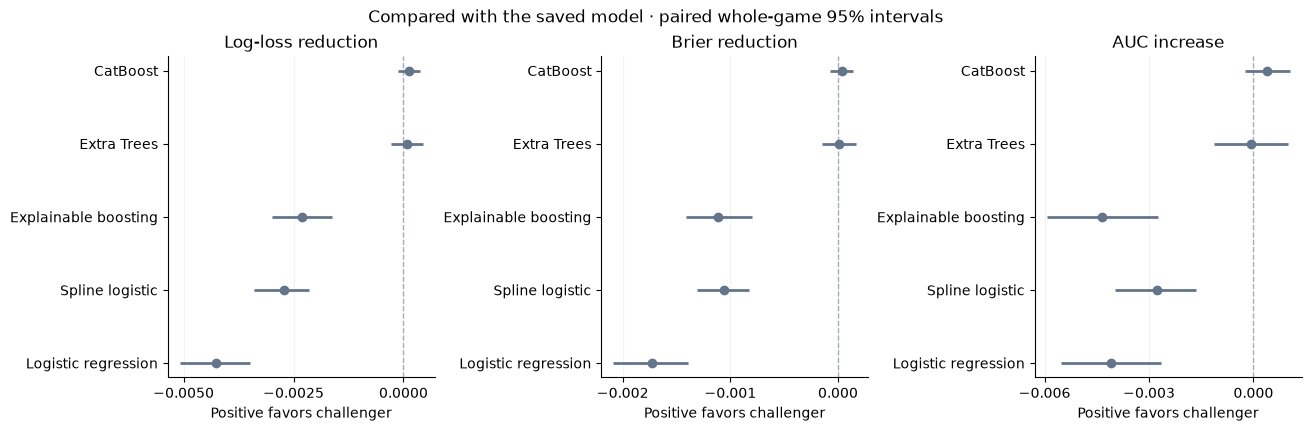

In [2]:
from matplotlib.ticker import MaxNLocator
DIRECTIONS = {'log_loss': -1, 'brier_score': -1, 'roc_auc': 1, 'ece_10': -1}
comparison_rows = []
indexed = metrics.set_index(['subset', 'model'])
for subset in slices:
    for name in models:
        if name == REFERENCE:
            continue
        for metric, direction in DIRECTIONS.items():
            difference = boots[(subset, name)][metric] - boots[(subset, REFERENCE)][metric]
            low, high, finite = interval(direction * difference)
            comparison_rows.append({'subset': subset, 'model': name, 'reference': REFERENCE,
                'metric': metric,
                'improvement': direction * (indexed.loc[(subset, name), metric]
                                            - indexed.loc[(subset, REFERENCE), metric]),
                'ci_low': low, 'ci_high': high, 'finite_draws': finite})
comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(RUN_DIR / 'paired_comparisons.csv', index=False)
display(comparisons.loc[comparisons.subset.eq('all')].assign(
    model=lambda d: d.model.map(LABELS))[['model', 'metric', 'improvement', 'ci_low', 'ci_high', 'finite_draws']].round(6))

challengers = [name for name in leaderboard.index if name not in [REFERENCE, 'training_make_rate']]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout='constrained')
for ax, metric, title in zip(axes, ['log_loss', 'brier_score', 'roc_auc'],
                            ['Log-loss reduction', 'Brier reduction', 'AUC increase']):
    ax.axvline(0, color='#a5adb6', linestyle='--', linewidth=1)
    for i, name in enumerate(challengers):
        row = comparisons.query('subset == "all" and model == @name and metric == @metric').iloc[0]
        color = '#087e70' if row.ci_low > 0 else '#64748b'
        ax.hlines(i, row.ci_low, row.ci_high, color=color, linewidth=2)
        ax.plot(row.improvement, i, 'o', color=color)
    ax.set(title=title, yticks=range(len(challengers)), yticklabels=[LABELS[n] for n in challengers],
           xlabel='Positive favors challenger')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=.15)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
fig.suptitle('Compared with the saved model · paired whole-game 95% intervals')
fig.savefig(RUN_DIR / 'figures' / 'paired_improvements.png', dpi=150)
plt.show()

## Calibration

Each point is a fixed probability bin; vertical intervals resample games. Hollow points have fewer than 100 shots and are labeled with their counts; the line connects supported bins only. The faint histogram shows where predictions occur. Reliability in nearly empty high/low-probability bins is uncertain. Better log loss or AUC does not by itself establish better calibration, and this plot does not fit a correction.

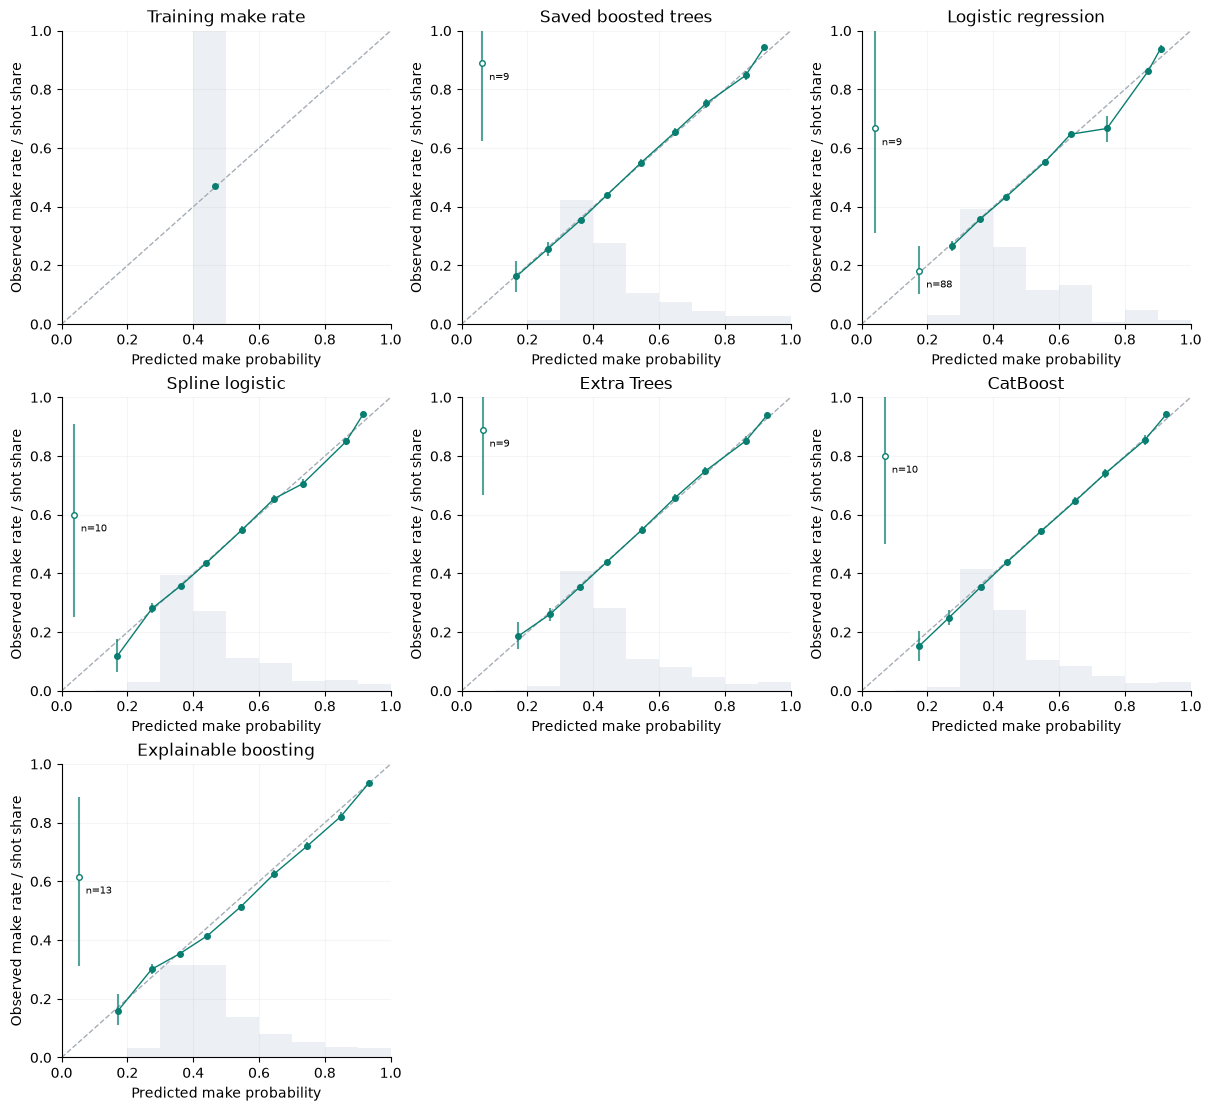

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11), layout='constrained')
for ax, name in zip(axes.flat, models):
    bins = calibration.loc[calibration.subset.eq('all') & calibration.model.eq(name) & calibration.shots.gt(0)]
    ax.plot([0, 1], [0, 1], '--', color='#a5adb6', linewidth=1)
    dense = bins.loc[bins.shots.ge(100)]
    ax.plot(dense.mean_probability, dense.observed_rate, color='#087e70', linewidth=1)
    for row in bins.itertuples():
        ax.vlines(row.mean_probability, row.observed_ci_low, row.observed_ci_high, color='#087e70', alpha=.7)
        ax.plot(row.mean_probability, row.observed_rate, 'o', markersize=4,
                markerfacecolor='#087e70' if row.shots >= 100 else 'white', markeredgecolor='#087e70')
        if row.shots < 100:
            ax.annotate(f'n={row.shots}', (row.mean_probability, row.observed_rate),
                        xytext=(5, -12), textcoords='offset points', fontsize=7)
    ax.hist(predictions[name], bins=np.linspace(0, 1, 11),
            weights=np.full(len(validation), 1/len(validation)), color='#cbd5e1', alpha=.35)
    ax.set(title=LABELS[name], xlim=(0, 1), ylim=(0, 1),
           xlabel='Predicted make probability', ylabel='Observed make rate / shot share')
    ax.grid(alpha=.12)
for ax in list(axes.flat)[len(models):]:
    ax.set_visible(False)
fig.savefig(RUN_DIR / 'figures' / 'calibration.png', dpi=150)
plt.show()

## Two-pointers, threes, and limited history

The sparse-shooter examples motivating this project need their own checks. Review log loss and Brier alongside calibration bias, sample sizes and paired intervals. A small subgroup with a favorable point estimate is not reliable evidence that an individual player's prediction is corrected.

In [9]:
slice_table = metrics.loc[metrics.subset.ne('all'),
    ['subset', 'model', 'shots', 'games', 'log_loss', 'brier_score', 'roc_auc', 'ece_10', 'calibration_bias']]
display(slice_table.assign(model=lambda d: d.model.map(LABELS)).round(6))
rare_comparisons = comparisons.loc[
    comparisons.subset.isin(['three_point_prior_attempts_lt25', 'three_point_prior_share_lt10pct'])
    & comparisons.metric.isin(['log_loss', 'brier_score'])
    & comparisons.model.ne('training_make_rate')]
display(rare_comparisons.assign(model=lambda d: d.model.map(LABELS))[
    ['subset', 'model', 'metric', 'improvement', 'ci_low', 'ci_high', 'finite_draws']].round(6))

,subset,model,shots,games,log_loss,brier_score,roc_auc,ece_10,calibration_bias
7,two_point,Training make rate,49583,480,0.701699,0.254269,0.500000,0.081790,-0.081790
8,two_point,Saved boosted trees,49583,480,0.630218,0.221565,0.679421,0.007110,0.000018
9,two_point,Logistic regression,49583,480,0.637168,0.224378,0.670202,0.007726,0.000672
10,two_point,Spline logistic,49583,480,0.634436,0.223301,0.673576,0.006402,0.000995
11,two_point,Extra Trees,49583,480,0.630143,0.221567,0.679473,0.005569,0.000020
12,two_point,CatBoost,49583,480,0.630084,0.221536,0.679588,0.005008,0.003361
13,two_point,Explainable boosting,49583,480,0.632006,0.222469,0.675846,0.018294,0.017691
14,three_point,Training make rate,35527,480,0.676843,0.241859,0.500000,0.108612,0.108612
15,three_point,Saved boosted trees,35527,480,0.649948,0.228737,0.545465,0.004705,0.004286
16,three_point,Logistic regression,35527,480,0.650438,0.228940,0.541935,0.003736,0.003400


,subset,model,metric,improvement,ci_low,ci_high,finite_draws
76,three_point_prior_attempts_lt25,Logistic regression,log_loss,-0.000437,-0.004114,0.003378,2000
77,three_point_prior_attempts_lt25,Logistic regression,brier_score,-0.000140,-0.001735,0.001495,2000
80,three_point_prior_attempts_lt25,Spline logistic,log_loss,-0.003418,-0.008083,0.001029,2000
81,three_point_prior_attempts_lt25,Spline logistic,brier_score,-0.000942,-0.002418,0.000605,2000
84,three_point_prior_attempts_lt25,Extra Trees,log_loss,-0.000716,-0.005372,0.003800,2000
85,three_point_prior_attempts_lt25,Extra Trees,brier_score,-0.000603,-0.002585,0.001345,2000
88,three_point_prior_attempts_lt25,CatBoost,log_loss,0.000979,-0.001638,0.003499,2000
89,three_point_prior_attempts_lt25,CatBoost,brier_score,0.000252,-0.000775,0.001261,2000
92,three_point_prior_attempts_lt25,Explainable boosting,log_loss,-0.002062,-0.007454,0.003424,2000
93,three_point_prior_attempts_lt25,Explainable boosting,brier_score,-0.000806,-0.003147,0.001655,2000


## Interpretation and next experiment

This validation period has already informed earlier feature choices and contains no playoff shots. These results are development evidence, not an independent final-product evaluation. Recorded action categories may contain information unavailable at shot release. Defender attribution describes observed attributed shots, not a causal measure of individual defensive skill.

A hierarchical logistic model remains a separate experiment: it would change the model structure and likely introduce player/type effects, so it is not represented by the spline model here. Any next tuning should use expanding chronological folds **inside training**. Evaluate calibration separately using chronological training data; settle development choices before evaluating the reserved test period once.

In [10]:
best_name = leaderboard.drop(index=['training_make_rate'], errors='ignore').index[0]
best = leaderboard.loc[best_name]
summary = (f'**Lowest validation log loss:** {LABELS[best_name]} — '
           f'{best.log_loss:.6f} log loss, {best.brier_score:.6f} Brier, {best.roc_auc:.6f} ROC AUC. ')
if best_name != REFERENCE:
    ll = comparisons.query('subset == "all" and model == @best_name and metric == "log_loss"').iloc[0]
    summary += (f'Log-loss reduction against the saved model: {ll.improvement:.6f} '
                f'(nominal paired 95% interval {ll.ci_low:.6f} to {ll.ci_high:.6f}). ')
summary += ('This is a fixed-setting development comparison; no calibration improvement or individual defensive skill '
            'is inferred from this ranking. The site model remains unchanged.')
display(Markdown(summary))
(RUN_DIR / 'summary.md').write_text(summary + '\n')

changed = [relative for relative, before in protected.items()
           if not (ROOT / relative).is_file() or sha256(ROOT / relative) != before]
assert not changed, f'Protected files changed: {changed[:10]}'
assert sha256(ROOT / 'models/matchup_model.json') == input_hashes['models/matchup_model.json']
notebook_source = nbformat.read(ROOT / 'HaydenModelComparison.ipynb', as_version=4)
source_text = '\n\n'.join(c.source for c in notebook_source.cells)
source_hash = hashlib.sha256(source_text.encode()).hexdigest()
code_hashes = {name: sha256(ROOT / name) for name in
               ['scripts/train_baselines.py', 'scripts/shooting_profile_features.py',
                'requirements-model-comparison.txt']}
manifest = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'status': 'complete',
    'run_id': RUN_ID, 'seed': SEED, 'threads': THREADS, 'python': sys.version,
    'feature_count': len(FEATURES), 'features': FEATURES,
    'train_shots': len(train), 'validation_shots': len(validation), 'validation_games': len(game_ids),
    'train_end': str(train.game_date.max().date()),
    'validation_start': str(validation.game_date.min().date()),
    'validation_end': str(validation.game_date.max().date()),
    'test_outcomes_read': 0, 'test_evaluated': False, 'calibration_adjustment_fitted': False,
    'new_hyperparameter_search': False, 'validation_used_for_early_stopping': False,
    'default_model_changed': False, 'benchmark_model_sha256': selection['model_sha256'],
    'benchmark_max_probability_error': benchmark_max_error,
    'models': list(models), 'bootstrap_replicates': len(draws),
    'bootstrap_source': 'reports/matchup_model/bootstrap_game_draws.npz',
    'bootstrap_limits': 'Nominal game-cluster percentile intervals; fixed fitted models; no retraining or selection uncertainty.',
    'input_hashes': input_hashes, 'code_hashes': code_hashes, 'model_hashes': model_hashes,
    'notebook_source_sha256': source_hash, 'versions': VERSIONS,
    'protected_artifacts_verified': len(protected), 'warnings': warning_records,
    'support_audit': profile_builder.audit, 'lowest_log_loss_model': best_name,
}
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
training_times.to_csv(RUN_DIR / 'timings.csv')
slice_counts.to_csv(RUN_DIR / 'slice_counts.csv', index=False)
split_summary.to_csv(RUN_DIR / 'split_summary.csv')
(RUN_DIR / 'environment.txt').write_text('\n'.join(sorted(
    f'{dist.metadata["Name"]}=={dist.version}' for dist in importlib.metadata.distributions())) + '\n')
print(f'Complete: {len(models)} models; {len(protected):,} protected artifacts unchanged.')
print('Saved results:', RUN_DIR)

**Lowest validation log loss:** CatBoost — 0.638327 log loss, 0.224524 Brier, 0.663640 ROC AUC. Log-loss reduction against the saved model: 0.000126 (nominal paired 95% interval -0.000113 to 0.000365). This is a fixed-setting development comparison; no calibration improvement or individual defensive skill is inferred from this ranking. The site model remains unchanged.

Complete: 7 models; 2,943 protected artifacts unchanged.
Saved results: /Users/haydenkellington/Desktop/EclipseHaydenPersonal/reports/model_comparison/20261116T043706371489Z


## References

- [CatBoost classifier and categorical features](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)
- [Explainable boosting classifier](https://interpret.ml/docs/python/api/ExplainableBoostingClassifier.html)
- [SplineTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html)
- [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

The actual parameters and package versions used in this run are recorded in the run directory. Existing source URLs and hashes remain in the original frozen snapshot manifests.